In [7]:
import numpy as np
import matplotlib.pyplot as plt

from softpotato.reactions import Species, ButlerVolmer
from softpotato.geometry import PlanarGeometry
from softpotato.techniques import CyclicVoltammetry, simulate

# Constants
D = 1e-9 # m^2/s
cR_bulk = 1 # mol/m^3 (1 mM)
cO_bulk = 0 # mol/m^3
area = 1e-5 # m^2 (1 cm^2)
E0 = 0 # V
n_rxn = 1
k0 = 1e-4 # m/s
alpha = 0.5

# Species definition
red = Species(
    name = "Red", 
    diffusivity = D, 
    bulk_concentration = cR_bulk, 
    standard_potential = E0, 
    n_electrons = -n_rxn
)

ox = Species(
    name = "Ox",
    diffusivity = D,
    bulk_concentration = cO_bulk,
    standard_potential = E0,
    n_electrons = n_rxn
)

# Set planar geometry
geometry = PlanarGeometry(area)

sr = np.linspace(0.1, 1, 10) # V/s
sim = []
for s in sr:

    # Define CV
    cv = CyclicVoltammetry(
        E_start = -0.4,
        E_vertex1 = 0.4,
        E_vertex2 = -0.4,
        scan_rate = s
    )

    # Run simulation
    sim.append(simulate(
        technique = cv,
        mechanism = [ox, red],
        geometry = geometry,
        kinetics = ButlerVolmer(k0=k0, alpha=alpha)
    )
)

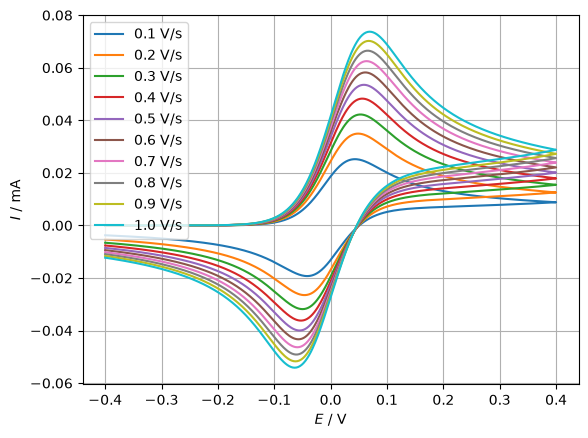

In [8]:
plt.figure()
for s in range(len(sr)):
    plt.plot(sim[s].potential, sim[s].current*1e3, label=f"{sr[s]:.1f} V/s")
plt.xlabel("$E$ / V")
plt.ylabel("$I$ / mA")
plt.grid()
plt.legend()
plt.show()

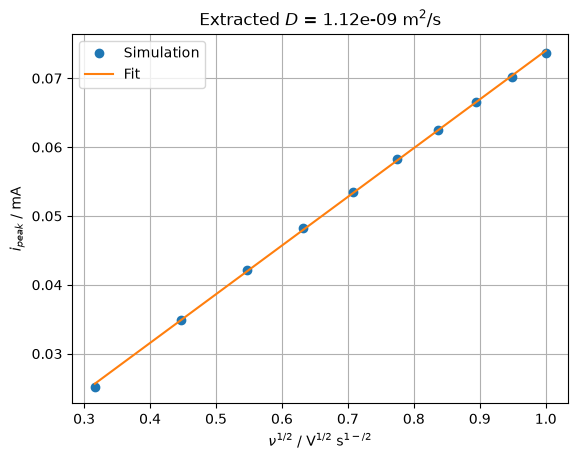

In [15]:
from softpotato.analytical.fitting import fit_randles_sevcik

i_sim = np.zeros(len(sim))
for s in range(len(sim)):
    i_sim[s] = np.max(sim[s].current)

fit = fit_randles_sevcik(
    scan_rate = sr, 
    peak_current = i_sim, 
    n = n_rxn, 
    area = area,
    c_bulk = cR_bulk,
    model = "irreversible"
)

sr_sqrt = np.sqrt(sr)

plt.figure()
plt.plot(sr_sqrt, i_sim*1e3, 'o', label="Simulation")
plt.plot(sr_sqrt, (fit.intercept + fit.slope*sr_sqrt)*1e3, '-', label="Fit")
plt.xlabel(r"$\nu^{1/2}$ / V$^{1/2}$ s$^{1-/2}$")
plt.ylabel(r"$i_{peak}$ / mA")
plt.title(fr"Extracted $D$ = {fit.d:.2e} m$^2$/s")
plt.grid()
plt.legend()
plt.show()